In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Ambiente preparado para Análise Exploratória de Dados!")
print("Pandas:", pd.__version__)

Ambiente preparado para Análise Exploratória de Dados!
Pandas: 3.0.6


## Aula 93 — Criando nosso primeiro DataFrame no Jupyter Notebook
Objetivo: compreender como o Pandas organiza dados em linhas e colunas e como visualizar informações de clientes.
Nesta aula, utilizaremos cinco registros fictícios apenas para aprendizagem. Posteriormente, carregaremos os dados da VIEW vw_dataset_churn_20250831 do PostgreSQL.

In [2]:
dados = {
    "cliente_id": [1, 2, 3, 4, 5],
    "total_atendimentos": [3, 1, 2, 0, 4],
    "churn_30_dias": [0, 0, 1, 0, 1]
}

df = pd.DataFrame(dados)

display(df)

print("Dimensões:", df.shape)
print("Colunas:", df.columns.tolist())

,cliente_id,total_atendimentos,churn_30_dias
0,1,3,0
1,2,1,0
2,3,2,1
3,4,0,0
4,5,4,1


Dimensões: (5, 3)
Colunas: ['cliente_id', 'total_atendimentos', 'churn_30_dias']


## Aula 94 — Análise inicial com head(), info() e describe()
Objetivo: aprender a inspecionar um conjunto de dados antes de iniciar análises estatísticas ou construir modelos de Machine Learning.
1. Conceitos teóricos
No Pandas, três métodos são especialmente úteis na Análise Exploratória de Dados (EDA):
Método	Finalidade
df.head()	Exibe as primeiras cinco linhas, por padrão
df.info()	Mostra colunas, tipos de dados e valores não nulos
df.describe()	Apresenta estatísticas descritivas das colunas numéricas

In [3]:
print("=== PRIMEIRAS LINHAS ===")
display(df.head())

print("=== INFORMAÇÕES DO DATAFRAME ===")
df.info()

print("=== ESTATÍSTICAS DESCRITIVAS ===")
display(df.describe())

=== PRIMEIRAS LINHAS ===


,cliente_id,total_atendimentos,churn_30_dias
0,1,3,0
1,2,1,0
2,3,2,1
3,4,0,0
4,5,4,1


=== INFORMAÇÕES DO DATAFRAME ===
<class 'pandas.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   cliente_id          5 non-null      int64
 1   total_atendimentos  5 non-null      int64
 2   churn_30_dias       5 non-null      int64
dtypes: int64(3)
memory usage: 252.0 bytes
=== ESTATÍSTICAS DESCRITIVAS ===


,cliente_id,total_atendimentos,churn_30_dias
count,5.000000,5.000000,5.000000
mean,3.000000,2.000000,0.400000
std,1.581139,1.581139,0.547723
min,1.000000,0.000000,0.000000
25%,2.000000,1.000000,0.000000
50%,3.000000,2.000000,0.000000
75%,4.000000,3.000000,1.000000
max,5.000000,4.000000,1.000000


## Aula 95 — Identificando valores ausentes com Pandas
Objetivo: aprender a identificar dados faltantes antes de realizar análises e preparar modelos de Machine Learning.
1. Conceito teórico
Em Ciência de Dados, valores ausentes podem ser representados por NaN, None ou pd.NA, dependendo do tipo de dado.
No Pandas, utilizamos:
- df.isna() para identificar valores ausentes.
- df.isna().sum() para contar os valores ausentes em cada coluna.
No nosso projeto, um cliente que nunca respondeu a uma pesquisa de satisfação pode apresentar media_satisfacao ausente. Isso não significa necessariamente que sua satisfação seja zero.

In [4]:
import numpy as np

df_eda = df.copy()

df_eda["media_satisfacao"] = [1.5, 4.0, np.nan, 5.0, 2.5]

print("=== DATAFRAME ===")
display(df_eda)

print("=== VALORES AUSENTES POR COLUNA ===")
print(df_eda.isna().sum())

print("=== TOTAL DE VALORES AUSENTES ===")
print(df_eda.isna().sum().sum())

=== DATAFRAME ===


,cliente_id,total_atendimentos,churn_30_dias,media_satisfacao
0,1,3,0,1.5
1,2,1,0,4.0
2,3,2,1,NaN
3,4,0,0,5.0
4,5,4,1,2.5


=== VALORES AUSENTES POR COLUNA ===
cliente_id            0
total_atendimentos    0
churn_30_dias         0
media_satisfacao      1
dtype: int64
=== TOTAL DE VALORES AUSENTES ===
1


## Aula 96 — Tratamento de valores ausentes com a mediana
Objetivo: aprender a substituir valores ausentes utilizando a mediana de uma variável numérica.
1. Conceito teórico
A mediana é o valor central de um conjunto de números ordenados. Quando existem dois valores centrais, utilizamos a média desses dois valores.
Na coluna media_satisfacao, temos:
Valores disponíveis em ordem crescente
1.5

2.5

4.0

5.0


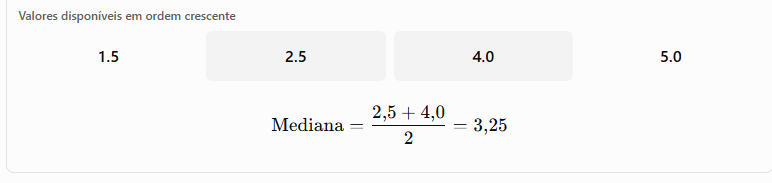


Assim, o valor ausente poderá ser preenchido com 3.25 neste exercício didático.

In [5]:
df_tratado = df_eda.copy()

mediana = df_tratado["media_satisfacao"].median()

df_tratado["media_satisfacao"] = (
    df_tratado["media_satisfacao"].fillna(mediana)
)

print("Mediana:", mediana)

print("=== DATAFRAME TRATADO ===")
display(df_tratado)

print("=== VALORES AUSENTES APÓS TRATAMENTO ===")
print(df_tratado.isna().sum())

Mediana: 3.25
=== DATAFRAME TRATADO ===


,cliente_id,total_atendimentos,churn_30_dias,media_satisfacao
0,1,3,0,1.50
1,2,1,0,4.00
2,3,2,1,3.25
3,4,0,0,5.00
4,5,4,1,2.50


=== VALORES AUSENTES APÓS TRATAMENTO ===
cliente_id            0
total_atendimentos    0
churn_30_dias         0
media_satisfacao      0
dtype: int64


## Aula 97 — Analisando a distribuição do churn
Objetivo: aprender a contar quantos clientes cancelaram e quantos permaneceram, utilizando o Pandas.
1. Conceito teórico
No projeto Customer Churn Prediction, a variável churn_30_dias é nosso target, ou seja, a variável que queremos prever.
- 0: cliente não cancelou no período analisado.
- 1: cliente cancelou efetivamente no período analisado.
O método value_counts() conta quantas vezes cada valor aparece em uma coluna.

In [6]:
print("=== DISTRIBUIÇÃO DO CHURN ===")
print(df_tratado["churn_30_dias"].value_counts().sort_index())

print("=== DISTRIBUIÇÃO PERCENTUAL ===")
print(
    df_tratado["churn_30_dias"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

print("=== TAXA DE CHURN ===")
taxa_churn = df_tratado["churn_30_dias"].mean() * 100
print(f"Taxa de churn: {taxa_churn:.2f}%")

=== DISTRIBUIÇÃO DO CHURN ===
churn_30_dias
0    3
1    2
Name: count, dtype: int64
=== DISTRIBUIÇÃO PERCENTUAL ===
churn_30_dias
0    60.0
1    40.0
Name: proportion, dtype: float64
=== TAXA DE CHURN ===
Taxa de churn: 40.00%


## Aula 98 — Visualizando a distribuição de churn com Matplotlib
Objetivo: construir nosso primeiro gráfico de barras no Jupyter Notebook para visualizar a quantidade de clientes com e sem cancelamento.
1. Conceito teórico
Um gráfico de barras permite comparar visualmente quantidades entre categorias.
No nosso projeto, utilizaremos duas categorias: clientes sem churn (0) e clientes com churn (1).
O Matplotlib é uma biblioteca Python utilizada para criar gráficos. A função plt.bar() constrói gráficos de barras verticais.

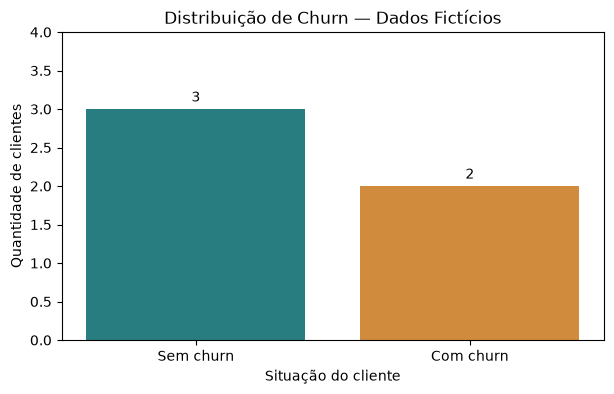

In [7]:
import matplotlib.pyplot as plt

contagem = (
    df_tratado["churn_30_dias"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

fig, ax = plt.subplots(figsize=(7, 4))

barras = ax.bar(
    ["Sem churn", "Com churn"],
    contagem.values,
    color=["#287D80", "#D18B3D"]
)

ax.set_title("Distribuição de Churn — Dados Fictícios")
ax.set_xlabel("Situação do cliente")
ax.set_ylabel("Quantidade de clientes")
ax.set_ylim(0, 4)

ax.bar_label(barras, padding=3)

plt.show()

## Aula 99 — Criando um gráfico de churn com Seaborn
Objetivo: aprender a utilizar o Seaborn para criar gráficos estatísticos e comparar sua abordagem com a do Matplotlib.
1. Conceito teórico
O Seaborn é uma biblioteca de visualização estatística construída sobre o Matplotlib.
Uma de suas funções é sns.countplot(), utilizada para contar automaticamente as ocorrências de cada categoria.
Diferentemente do exercício anterior, não precisaremos calcular previamente as contagens com value_counts().

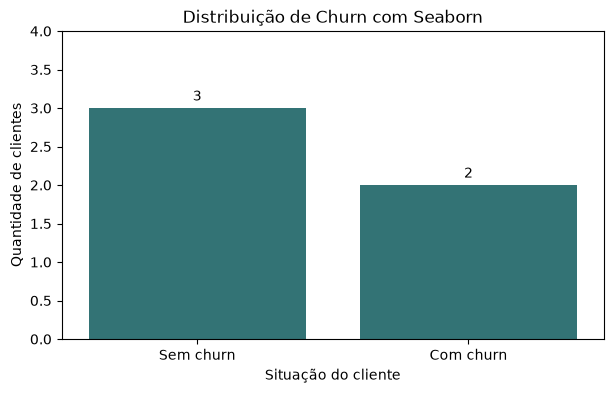

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 4))

sns.countplot(
    data=df_tratado,
    x="churn_30_dias",
    order=[0, 1],
    color="#287D80",
    ax=ax
)

ax.set_title("Distribuição de Churn com Seaborn")
ax.set_xlabel("Situação do cliente")
ax.set_ylabel("Quantidade de clientes")
ax.set_xticks([0, 1])
ax.set_xticklabels(["Sem churn", "Com churn"])

for barras in ax.containers:
    ax.bar_label(barras, padding=3)

ax.set_ylim(0, 4)

plt.show()

## Aula 100 — Identificando a relação entre atendimentos e churn
Objetivo: investigar se os clientes que cancelaram o serviço apresentam uma quantidade diferente de atendimentos em relação aos que permaneceram.
Nesta aula, utilizaremos o método groupby() do Pandas.
1. Conceito teórico
O método groupby() permite agrupar registros por uma categoria e calcular estatísticas para cada grupo.

In [9]:
print("=== MÉDIA DE ATENDIMENTOS POR CHURN ===")

media_atendimentos = (
    df_tratado
    .groupby("churn_30_dias")["total_atendimentos"]
    .mean()
    .round(2)
)

print(media_atendimentos)

print("=== QUANTIDADE DE CLIENTES POR GRUPO ===")

quantidade_clientes = (
    df_tratado
    .groupby("churn_30_dias")["cliente_id"]
    .count()
)

print(quantidade_clientes)

=== MÉDIA DE ATENDIMENTOS POR CHURN ===
churn_30_dias
0    1.33
1    3.00
Name: total_atendimentos, dtype: float64
=== QUANTIDADE DE CLIENTES POR GRUPO ===
churn_30_dias
0    3
1    2
Name: cliente_id, dtype: int64


## Aula 101 — Conectando o Jupyter Notebook ao PostgreSQL
Agora iniciaremos uma etapa importante do Portfólio 1 de 5: deixar de utilizar exclusivamente os cinco registros didáticos e começar a analisar os dados provenientes do banco PostgreSQL.
Objetivo: consultar a VIEW vw_dataset_churn_20250831 diretamente no notebook 01_exploracao_dados.ipynb.

### Aula 102 — Conexão segura do Jupyter Notebook ao PostgreSQL
Objetivo: estabelecer uma conexão com o banco customer_churn_db sem armazenar a senha no código-fonte.
2. Conceito teórico
Em projetos profissionais, credenciais de banco de dados não devem ser inseridas diretamente em notebooks, arquivos Python ou repositórios GitHub.
Vamos utilizar uma variável de ambiente chamada PGPASSWORD. O Python poderá acessá-la durante a execução, sem que a senha apareça no código.
Importante: o notebook deve utilizar o mesmo ambiente em que a variável foi configurada. Como o kernel do Jupyter pode já estar em execução, será necessário reiniciá-lo depois de definir a variável.

In [10]:
import getpass
import psycopg

senha = getpass.getpass("Senha do PostgreSQL: ")

try:
    with psycopg.connect(
        host="localhost",
        port=5432,
        dbname="customer_churn_db",
        user="postgres",
        password=senha
    ) as conexao:
        with conexao.cursor() as cursor:
            cursor.execute("SELECT current_database(), current_user;")
            resultado = cursor.fetchone()

            print("Conexão estabelecida com sucesso!")
            print("Banco:", resultado[0])
            print("Usuário:", resultado[1])
finally:
    del senha

Conexão estabelecida com sucesso!
Banco: customer_churn_db
Usuário: postgres


## Aula 103 — Importando dados do PostgreSQL para o Pandas
Objetivo: consultar a VIEW vw_dataset_churn_20250831 e transformar os registros do PostgreSQL em um DataFrame.
Essa etapa é importante porque começaremos a utilizar o dataset do projeto, em vez dos cinco registros criados manualmente para aprendizagem.
1. Conceito teórico
O método pd.read_sql_query() permite executar uma consulta SQL e carregar seu resultado em um DataFrame do Pandas.

In [11]:
import getpass
import psycopg
import pandas as pd

senha = getpass.getpass("Senha do PostgreSQL: ")

try:
    with psycopg.connect(
        host="localhost",
        port=5432,
        dbname="customer_churn_db",
        user="postgres",
        password=senha
    ) as conexao:
        with conexao.cursor() as cursor:
            cursor.execute("""
                SELECT *
                FROM vw_dataset_churn_20250831
                ORDER BY cliente_id
            """)

            colunas = [coluna.name for coluna in cursor.description]
            registros = cursor.fetchall()

    df_postgres = pd.DataFrame(registros, columns=colunas)

    print("=== DATASET IMPORTADO DO POSTGRESQL ===")
    print(df_postgres.to_string(index=False))

    print("\nDimensões:", df_postgres.shape)

finally:
    del senha

=== DATASET IMPORTADO DO POSTGRESQL ===
 cliente_id data_referencia  total_atendimentos  atendimentos_abertos media_satisfacao  churn_30_dias
          1      2025-08-31                   3                     1             1.50              0
          2      2025-08-31                   1                     0             4.00              0
          3      2025-08-31                   1                     0             5.00              0
          5      2025-08-31                   0                     0             None              1

Dimensões: (4, 6)


## Aula 104 — Verificação da qualidade dos dados importados
Objetivo: identificar os tipos das colunas e os valores ausentes do DataFrame df_postgres.
Antes de construir um modelo de Machine Learning, precisamos conhecer a estrutura dos dados recebidos.
2. Conceito teórico
O Pandas oferece dois recursos importantes:
- df.dtypes: mostra o tipo de cada coluna.
- df.isna().sum(): conta os valores ausentes em cada coluna.
No nosso dataset, a coluna media_satisfacao possui um valor ausente para o cliente 5. Isso representa a ausência de uma avaliação registrada, e não necessariamente uma satisfação igual a zero.
Além disso, valores numéricos vindos do PostgreSQL podem chegar ao Pandas com o tipo object, especialmente quando são representados por Decimal.

In [12]:
print("=== TIPOS DAS COLUNAS ===")
print(df_postgres.dtypes)

print("\n=== VALORES AUSENTES POR COLUNA ===")
print(df_postgres.isna().sum())

print("\n=== TOTAL DE VALORES AUSENTES ===")
print(df_postgres.isna().sum().sum())

=== TIPOS DAS COLUNAS ===
cliente_id               int64
data_referencia         object
total_atendimentos       int64
atendimentos_abertos     int64
media_satisfacao        object
churn_30_dias            int64
dtype: object

=== VALORES AUSENTES POR COLUNA ===
cliente_id              0
data_referencia         0
total_atendimentos      0
atendimentos_abertos    0
media_satisfacao        1
churn_30_dias           0
dtype: int64

=== TOTAL DE VALORES AUSENTES ===
1


## Aula 105 — Conversão dos tipos de dados com Pandas
Objetivo: converter data_referencia para datetime64[ns] e media_satisfacao para float64, preservando o valor ausente.
2. Conceito teórico
O Pandas oferece funções específicas para converter dados:
- pd.to_datetime(): converte valores para um tipo de data.
- pd.to_numeric(): converte valores para tipos numéricos.
Por exemplo, a satisfação 1.50, originalmente armazenada como Decimal pelo PostgreSQL, pode ser convertida para um número decimal do Pandas.
Já um valor ausente pode passar a ser representado por NaN, sem precisar inventar uma nota para o cliente.

In [13]:
df_postgres_tratado = df_postgres.copy()

df_postgres_tratado["data_referencia"] = pd.to_datetime(
    df_postgres_tratado["data_referencia"]
)

df_postgres_tratado["media_satisfacao"] = pd.to_numeric(
    df_postgres_tratado["media_satisfacao"],
    errors="coerce"
)

print("=== TIPOS APÓS CONVERSÃO ===")
print(df_postgres_tratado.dtypes)

print("\n=== DATASET APÓS CONVERSÃO ===")
print(df_postgres_tratado.to_string(index=False))

print("\n=== VALORES AUSENTES ===")
print(df_postgres_tratado.isna().sum())

=== TIPOS APÓS CONVERSÃO ===
cliente_id                      int64
data_referencia         datetime64[s]
total_atendimentos              int64
atendimentos_abertos            int64
media_satisfacao              float64
churn_30_dias                   int64
dtype: object

=== DATASET APÓS CONVERSÃO ===
 cliente_id data_referencia  total_atendimentos  atendimentos_abertos  media_satisfacao  churn_30_dias
          1      2025-08-31                   3                     1               1.5              0
          2      2025-08-31                   1                     0               4.0              0
          3      2025-08-31                   1                     0               5.0              0
          5      2025-08-31                   0                     0               NaN              1

=== VALORES AUSENTES ===
cliente_id              0
data_referencia         0
total_atendimentos      0
atendimentos_abertos    0
media_satisfacao        1
churn_30_dias           0


## Aula 106 — Análise da distribuição de churn no PostgreSQL
Objetivo: calcular a quantidade de clientes com e sem churn e a taxa de cancelamento da nossa base sintética.
Agora utilizaremos o DataFrame df_postgres_tratado, que representa os registros importados do PostgreSQL.
2. Conceito teórico
A variável churn_30_dias é o nosso target, ou seja, a variável que futuramente desejamos prever.
- 0: cliente não cancelou efetivamente o serviço no período.
- 1: cliente cancelou efetivamente o serviço no período.

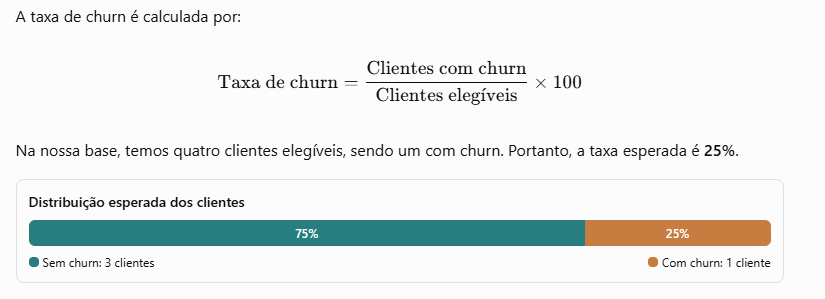

In [14]:
print("=== DISTRIBUIÇÃO DE CHURN ===")

distribuicao = (
    df_postgres_tratado["churn_30_dias"]
    .value_counts()
    .sort_index()
)

print(distribuicao)

print("\n=== TAXA DE CHURN ===")

taxa_churn = (
    df_postgres_tratado["churn_30_dias"].mean() * 100
)

print(f"Taxa de churn: {taxa_churn:.2f}%")

print("\n=== TOTAL DE CLIENTES ===")

print("Clientes elegíveis:", len(df_postgres_tratado))

=== DISTRIBUIÇÃO DE CHURN ===
churn_30_dias
0    3
1    1
Name: count, dtype: int64

=== TAXA DE CHURN ===
Taxa de churn: 25.00%

=== TOTAL DE CLIENTES ===
Clientes elegíveis: 4


## Aula 107 — Identificando o desbalanceamento de classes
Objetivo: compreender a distribuição percentual das classes 0 e 1 e verificar se existe desequilíbrio na variável-alvo.
2. Conceito teórico
Em problemas de classificação, chamamos de classes os possíveis valores que o modelo deve prever.
No nosso projeto:
- Classe 0: cliente sem churn.
- Classe 1: cliente com churn.

In [15]:
print("=== DISTRIBUIÇÃO PERCENTUAL DAS CLASSES ===")

percentuais = (
    df_postgres_tratado["churn_30_dias"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

print(percentuais)

print("\n=== MODELO BASELINE: PREVER SEMPRE ZERO ===")

total_clientes = len(df_postgres_tratado)

acertos_baseline = (
    df_postgres_tratado["churn_30_dias"] == 0
).sum()

acuracia_baseline = (
    acertos_baseline / total_clientes
) * 100

print(f"Acurácia baseline: {acuracia_baseline:.2f}%")
print("Cancelamentos identificados pelo baseline: 0")

=== DISTRIBUIÇÃO PERCENTUAL DAS CLASSES ===
churn_30_dias
0    75.0
1    25.0
Name: proportion, dtype: float64

=== MODELO BASELINE: PREVER SEMPRE ZERO ===
Acurácia baseline: 75.00%
Cancelamentos identificados pelo baseline: 0


## Aula 108 — Matriz de confusão: entendendo os erros do modelo
Objetivo: aprender a interpretar uma matriz de confusão, uma ferramenta essencial para avaliar modelos de classificação.
2. Conceito teórico
A matriz de confusão compara os valores reais (y_true) com as previsões (y_pred) de um classificador.
No nosso projeto, consideramos churn (1) como a classe positiva.

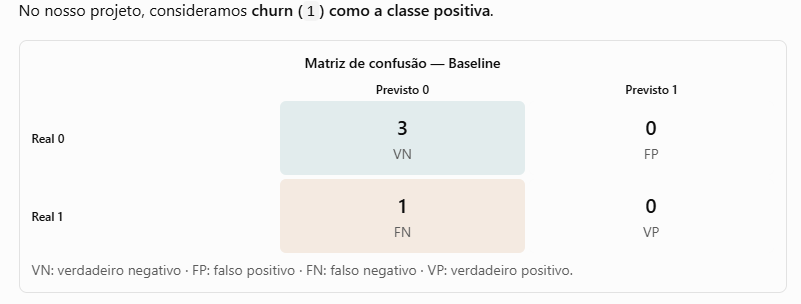

In [16]:
import numpy as np
from sklearn.metrics import confusion_matrix

# Valores reais da nossa base
y_true = df_postgres_tratado["churn_30_dias"]

# Baseline: prever que nenhum cliente cancelará
y_pred = np.zeros(len(y_true), dtype=int)

# Calcular a matriz de confusão
matriz = confusion_matrix(y_true, y_pred, labels=[0, 1])

vn, fp, fn, vp = matriz.ravel()

print("=== MATRIZ DE CONFUSÃO ===")
print(matriz)

print("\n=== COMPONENTES DA MATRIZ ===")
print("Verdadeiros negativos:", vn)
print("Falsos positivos:", fp)
print("Falsos negativos:", fn)
print("Verdadeiros positivos:", vp)

=== MATRIZ DE CONFUSÃO ===
[[3 0]
 [1 0]]

=== COMPONENTES DA MATRIZ ===
Verdadeiros negativos: 3
Falsos positivos: 0
Falsos negativos: 1
Verdadeiros positivos: 0


## Aula 109 — Recall: capacidade de identificar clientes que cancelam
Objetivo: aprender a calcular e interpretar o recall da classe positiva (churn = 1).
2. Conceito teórico
O recall, também chamado de sensibilidade, mede a proporção dos casos realmente positivos que o classificador conseguiu identificar.

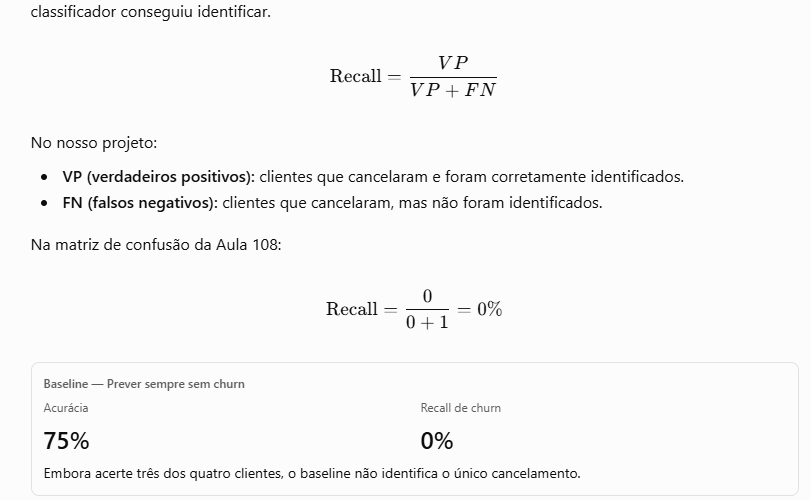



In [17]:
from sklearn.metrics import recall_score, accuracy_score

# Reutilizamos y_true e y_pred da Aula 108
recall = recall_score(
    y_true,
    y_pred,
    pos_label=1,
    zero_division=0
)

acuracia = accuracy_score(y_true, y_pred)

print("=== AVALIAÇÃO DO BASELINE ===")
print(f"Acurácia: {acuracia * 100:.2f}%")
print(f"Recall da classe churn: {recall * 100:.2f}%")

print("\n=== INTERPRETAÇÃO ===")

if recall == 0:
    print("O baseline não identificou nenhum cliente com churn.")
else:
    print("O baseline identificou parte dos clientes com churn.")

=== AVALIAÇÃO DO BASELINE ===
Acurácia: 75.00%
Recall da classe churn: 0.00%

=== INTERPRETAÇÃO ===
O baseline não identificou nenhum cliente com churn.


## Aula 110 — Precision: confiabilidade das previsões de churn
Objetivo: compreender a métrica precision (precisão da classe positiva) e sua diferença em relação ao recall.
2. Conceito teórico
A precision mede quantos clientes realmente cancelaram entre aqueles que o modelo classificou como churn.

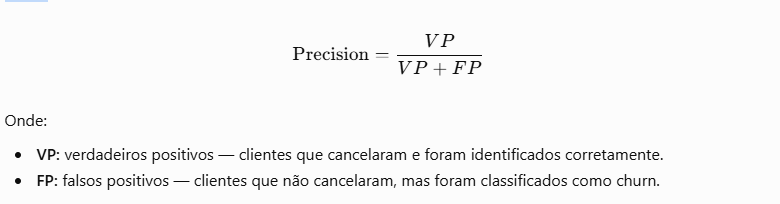


In [18]:
from sklearn.metrics import precision_score, recall_score, accuracy_score

# Reutilizamos os valores reais e as previsões da Aula 108
precision = precision_score(
    y_true,
    y_pred,
    pos_label=1,
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    pos_label=1,
    zero_division=0
)

acuracia = accuracy_score(y_true, y_pred)

print("=== MÉTRICAS DO BASELINE ===")
print(f"Acurácia: {acuracia * 100:.2f}%")
print(f"Precision da classe churn: {precision * 100:.2f}%")
print(f"Recall da classe churn: {recall * 100:.2f}%")

print("\n=== INTERPRETAÇÃO ===")

if (y_pred == 1).sum() == 0:
    print("O baseline não realizou previsões positivas de churn.")
    print("Precision indefinida; configurada como 0.00% no cálculo.")

=== MÉTRICAS DO BASELINE ===
Acurácia: 75.00%
Precision da classe churn: 0.00%
Recall da classe churn: 0.00%

=== INTERPRETAÇÃO ===
O baseline não realizou previsões positivas de churn.
Precision indefinida; configurada como 0.00% no cálculo.


## Aula 111 — F1-score: equilibrando precision e recall
Objetivo: compreender o F1-score e calcular essa métrica para o nosso baseline.
2. Conceito teórico
O F1-score combina precision e recall por meio da média harmônica:

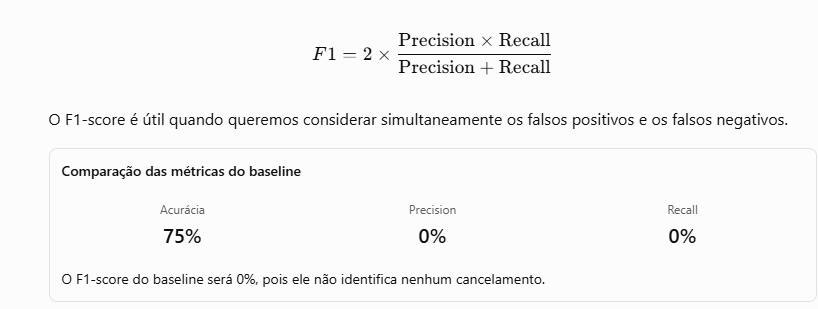

In [19]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Reutilizamos y_true e y_pred das aulas anteriores

acuracia = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true, y_pred, pos_label=1, zero_division=0
)

recall = recall_score(
    y_true, y_pred, pos_label=1, zero_division=0
)

f1 = f1_score(
    y_true, y_pred, pos_label=1, zero_division=0
)

print("=== MÉTRICAS COMPLETAS DO BASELINE ===")
print(f"Acurácia: {acuracia * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall: {recall * 100:.2f}%")
print(f"F1-score: {f1 * 100:.2f}%")

=== MÉTRICAS COMPLETAS DO BASELINE ===
Acurácia: 75.00%
Precision: 0.00%
Recall: 0.00%
F1-score: 0.00%
